# Homework9 Jiayan Wang

# Age Prediction from CpG Methylation

Compare Ridge, LASSO, and Elastic Net using 100 simulated CpG features.
Use the same 80/20 training–test split for all models.
The sample ID is excluded from prediction.

These simulated data do not support biological conclusions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = (
    r"D:\xwechat_files\wxid_x4e0znrem8gc12_eb3c"
    r"\msg\file\2026-11\SIMULATED_CpG_age_1000.csv"
)
df = pd.read_csv(path)

X = df.filter(regex=r"^sim_CpG_").astype(float)
y = df["age_years"].astype(float)

assert X.shape[1] == 100
assert np.isfinite(X.to_numpy()).all() and np.isfinite(y).all()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training: {len(y_train)}; Test: {len(y_test)}; Features: {X.shape[1]}")
display(df.head())

Training: 800; Test: 200; Features: 100


,sample_id,age_years,sim_CpG_001,sim_CpG_002,sim_CpG_003,sim_CpG_004,sim_CpG_005,sim_CpG_006,sim_CpG_007,sim_CpG_008,...,sim_CpG_091,sim_CpG_092,sim_CpG_093,sim_CpG_094,sim_CpG_095,sim_CpG_096,sim_CpG_097,sim_CpG_098,sim_CpG_099,sim_CpG_100
0,SIM_0001,50.97,0.202185,0.713494,0.469755,0.157838,0.393908,0.649819,0.845340,0.343914,...,0.710372,0.555714,0.864863,0.325214,0.818733,0.248756,0.514383,0.398787,0.622613,0.240704
1,SIM_0002,84.13,0.148112,0.755920,0.443261,0.125685,0.524919,0.524400,0.566065,0.159824,...,0.774816,0.825599,0.340620,0.650013,0.933259,0.200172,0.862190,0.332208,0.161940,0.266044
2,SIM_0003,74.46,0.447534,0.839715,0.743722,0.181233,0.807770,0.840044,0.874211,0.194736,...,0.884544,0.675575,0.743100,0.668620,0.890125,0.388891,0.739341,0.449927,0.505124,0.581857
3,SIM_0004,64.26,0.381498,0.828250,0.725128,0.304075,0.564085,0.605080,0.879044,0.126634,...,0.649214,0.696389,0.630099,0.835285,0.769667,0.428705,0.896175,0.547957,0.554755,0.142794
4,SIM_0005,22.21,0.212218,0.603949,0.897399,0.548161,0.263523,0.612231,0.646722,0.052869,...,0.760072,0.576407,0.973626,0.422773,0.761299,0.517361,0.607686,0.715961,0.654517,0.204359


## Model Fitting and Evaluation

- **Ridge:** L2 regularization shrinks coefficients, usually retaining all features.
- **LASSO:** L1 regularization can set coefficients to zero.
- **Elastic Net:** combines L1 and L2 regularization.

Select hyperparameters using five-fold cross-validation on the training set,
minimizing validation RMSE. A pipeline fits standardization within each fold
to prevent data leakage.

Report training and test MAE, RMSE, and R².
Lower MAE/RMSE and higher R² indicate better predictions.
Count nonzero coefficients using a tolerance of 10⁻⁸, excluding the intercept.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

specs = {
    "Ridge": (
        Ridge(),
        {"ridge__alpha": np.logspace(-4, 4, 30)}
    ),
    "LASSO": (
        Lasso(max_iter=100000, tol=1e-6),
        {"lasso__alpha": np.logspace(-4, 1, 30)}
    ),
    "Elastic Net": (
        ElasticNet(max_iter=100000, tol=1e-6),
        {
            "elasticnet__alpha": np.logspace(-4, 1, 30),
            "elasticnet__l1_ratio": [0.2, 0.5, 0.8]
        }
    )
}

models, predictions, rows = {}, {}, []

for name, (model, grid) in specs.items():
    search = GridSearchCV(
        make_pipeline(StandardScaler(), model),
        grid,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    models[name] = search.best_estimator_
    predictions[name] = (
        models[name].predict(X_train),
        models[name].predict(X_test)
    )
    nonzero = np.count_nonzero(
        np.abs(models[name].steps[-1][1].coef_) > 1e-8
    )

    for split, actual, predicted in [
        ("Training", y_train, predictions[name][0]),
        ("Test", y_test, predictions[name][1])
    ]:
        rows.append({
            "Model": name,
            "Split": split,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted),
            "Nonzero": nonzero
        })

    print(f"{name}: {search.best_params_}")

results = pd.DataFrame(rows).set_index(["Model", "Split"])
display(results.round(4))

Ridge: {'ridge__alpha': np.float64(221.22162910704503)}
LASSO: {'lasso__alpha': np.float64(0.4175318936560405)}
Elastic Net: {'elasticnet__alpha': np.float64(0.4175318936560405), 'elasticnet__l1_ratio': 0.8}


MAE    RMSE      R2  Nonzero
Model       Split                                    
Ridge       Training  5.5013  6.8013  0.8711      100
            Test      6.3514  7.8729  0.8300      100
LASSO       Training  5.6508  6.9752  0.8645       32
            Test      6.3854  7.8822  0.8296       32
Elastic Net Training  5.6236  6.9537  0.8653       39
            Test      6.3818  7.8881  0.8294       39

## Actual versus Predicted Age

Blue points represent training samples; orange points represent test samples.
The dashed line shows perfect prediction (y = x).
Points closer to this line indicate smaller errors.
All panels use identical axis limits.

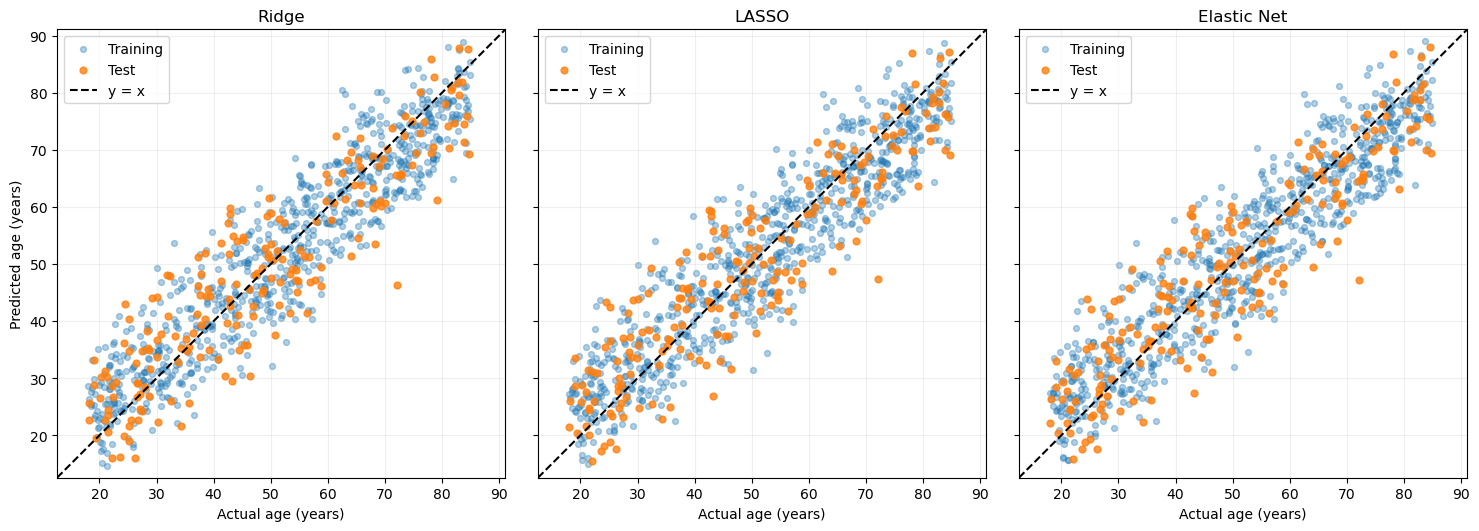

In [7]:
values = np.concatenate(
    [y.to_numpy()] +
    [p for pair in predictions.values() for p in pair]
)
limits = [values.min() - 2, values.max() + 2]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True
)

for ax, (name, (train_pred, test_pred)) in zip(axes, predictions.items()):
    ax.scatter(
        y_train, train_pred, color="tab:blue",
        alpha=0.35, s=18, label="Training"
    )
    ax.scatter(
        y_test, test_pred, color="tab:orange",
        alpha=0.8, s=24, label="Test"
    )
    ax.plot(limits, limits, "k--", label="y = x")
    ax.set(
        title=name, xlabel="Actual age (years)",
        xlim=limits, ylim=limits
    )
    ax.set_aspect("equal")
    ax.legend()
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Predicted age (years)")
plt.tight_layout()
plt.show()

## Comparison and Discussion

- **Accuracy:** compare test MAE, RMSE, and R². The summary below identifies
  the lowest test RMSE for this split.
- **Overfitting:** a much lower training RMSE than test RMSE may indicate
  overfitting. Interpret the gap together with the absolute errors.
- **Feature selection:** Ridge usually retains all features. LASSO can produce
  a sparse model. Elastic Net combines sparsity with L2 shrinkage and may retain
  groups of correlated features. Actual feature counts depend on the fitted models.

Small differences from a single random split do not establish consistent superiority.
Selected CpGs should not be interpreted as causal aging markers.

In [6]:
train = results.xs("Training", level="Split")
test = results.xs("Test", level="Split")

display(pd.DataFrame({
    "Train RMSE": train["RMSE"],
    "Test RMSE": test["RMSE"],
    "RMSE gap": test["RMSE"] - train["RMSE"],
    "Nonzero coefficients": test["Nonzero"]
}).round(4))

best = test["RMSE"].idxmin()

display(Markdown(
    f"**Lowest test RMSE in this split: {best}.** "
    f"MAE = {test.loc[best, 'MAE']:.3f} years; "
    f"RMSE = {test.loc[best, 'RMSE']:.3f} years; "
    f"R² = {test.loc[best, 'R2']:.4f}."
))

,Train RMSE,Test RMSE,RMSE gap,Nonzero coefficients
Model,,,,
Ridge,6.8013,7.8729,1.0716,100
LASSO,6.9752,7.8822,0.9070,32
Elastic Net,6.9537,7.8881,0.9343,39


**Lowest test RMSE in this split: Ridge.** MAE = 6.351 years; RMSE = 7.873 years; R² = 0.8300.